# Лабораторная работа 1 - Введение в язык программирования Python

Необходимо случайным образом создать набор данных (датасет) состоящий перечисленных полей, при этом функция распределения случайной величины для каждого из полей задана согласно вашему варианту.

| признак | смысл | распределение |
|---|---|---|
| `unit_price` | цена одного товара | Экспоненциальное распределение λ = 40; |
| `qty` | сколько штук в заказе | Пуассона распределение λ = 2; |
| `discount` | скидка, доля от 0 до 0.35 | Нормальное распределение от 0 до 0.35; |
| `delivery_fee` | цена доставки | Нормальное распределение от 0 до 25; |

Вычисляемые признаки

| признак | смысл | распределение |
|---|---|---|
| `order_total` | итог по заказу | unit_price·qty·(1-discount) + delivery_fee |
| `subtotal` | сумма без скидки и доставки | unit_price * qty |
| `avg_item_cost` | средняя цена одной позиции  | subtotal / qty |
| `discount_value` | величина скидки в деньгах | subtotal * discount |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng()

n = 10_000
buff = int(n * 1.5)

unit_price = rng.exponential(scale=40, size=buff)
qty = rng.poisson(lam=2, size=buff)
discount = rng.uniform(0, 0.35, buff)
delivery_fee = rng.uniform(0, 0.25, buff)

mask = qty > 0
qty = qty[mask][:n]
unit_price = unit_price[mask][:n]
discount = discount[mask][:n]
delivery_fee = delivery_fee[mask][:n]

order_total = unit_price * qty * (1 - discount) + delivery_fee
subtotal = unit_price * qty
avg_item_cost = subtotal / qty
discount_value = subtotal * discount

df = pd.DataFrame({
    "unit_price": unit_price,
    "qty": qty,
    "discount": discount,
    "delivery_fee": delivery_fee,
    "subtotal": subtotal,
    "discount_value": discount_value,
    "avg_item_cost": avg_item_cost,
    "order_total": order_total,
})
df

,unit_price,qty,discount,delivery_fee,subtotal,discount_value,avg_item_cost,order_total
0,28.135528,2,0.022787,0.120015,56.271056,1.282240,28.135528,55.108830
1,39.209578,7,0.075941,0.161134,274.467043,20.843385,39.209578,253.784792
2,12.024630,3,0.190040,0.078995,36.073890,6.855482,12.024630,29.297403
3,39.722517,1,0.001187,0.011523,39.722517,0.047138,39.722517,39.686902
4,9.912961,1,0.069579,0.006697,9.912961,0.689731,9.912961,9.229927
...,...,...,...,...,...,...,...,...
9995,18.236923,1,0.285520,0.247338,18.236923,5.206997,18.236923,13.277264
9996,54.596346,4,0.325973,0.191953,218.385385,71.187694,54.596346,147.389644
9997,3.578696,4,0.126253,0.150131,14.314783,1.807291,3.578696,12.657623
9998,5.930825,3,0.235568,0.226522,17.792476,4.191339,5.930825,13.827660


Далее для вашего набора данных надо найти следующие оценки для каждого из полей отдельно:
1. мат ожидание
2. дисперсию
$$\bar x = \frac{1}{n}\sum_{i=1}^{n} x_i \qquad\qquad s^2 = \frac{1}{n-1}\sum_{i=1}^{n} (x_i - \bar x)^2$$
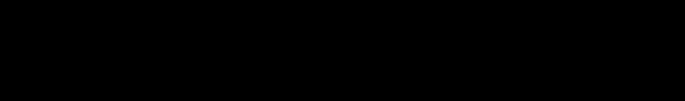
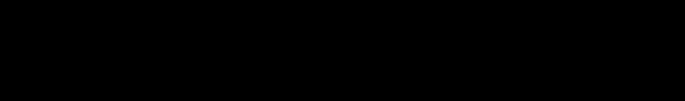

In [17]:
def mean(x):
    return np.sum(x) / len(x)

def var(x):
    m = mean(x)
    return np.sum((x - m) ** 2) / (len(x) - 1)

stats_rows = {}

for col in df:
    M = mean(df[col])
    Var = var(df[col])

    stats_rows[col] = {
        "mean": M,
        "variance": Var
    }

stats = pd.DataFrame(stats_rows).T
stats

,mean,variance
unit_price,40.470645,1579.271409
qty,2.319200,1.613673
discount,0.175175,0.010155
delivery_fee,0.127752,0.005246
subtotal,93.158728,13092.310410
discount_value,16.205873,610.241776
avg_item_cost,40.470645,1579.271409
order_total,77.080607,9169.988159


Дополнительно найти:
1.  вылеты согласно правилу 3-х сигм (для каждого из полей)

$$s = \sqrt{s^2} \qquad\qquad \text{выброс: } |x - \bar x| > 3s$$

In [41]:
outliners = {}
outliners_mask = {}
for col in df:
    M = mean(df[col])
    std = np.sqrt(var(df[col]))
    mask = np.abs(df[col] - M) > 3 * std

    outliners_mask[col] = mask

    outliners[col] = {
        'count': np.sum(mask)
    }

pd.DataFrame(outliners).T

,count
unit_price,179
qty,65
discount,0
delivery_fee,0
subtotal,222
discount_value,220
avg_item_cost,179
order_total,222


## 4. Ковариация и корреляция Пирсона (вручную)

$$cov(x, y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar x)(y_i - \bar y) \qquad\qquad r = \frac{cov(x,y)}{s_x \, s_y}$$

In [39]:
def cov(x, y):
    Mx = mean(x)
    My = mean(y)
    return np.sum((x - Mx) * (y - My)) / (len(x) - 1)

def pirson(x, y):
    Sx = var(x) ** 0.5
    Sy = var(y) ** 0.5
    return cov(x, y) / (Sx * Sy)

cols = df.columns.tolist()
corr_matrix = np.zeros((len(cols), len(cols)))
for i, col1 in enumerate(cols):
    for j, col2 in enumerate(cols):
        corr_matrix[i, j] = pirson(df[col1], df[col2])

corr_df = pd.DataFrame(corr_matrix, index=cols, columns=cols)
corr_df

,unit_price,qty,discount,delivery_fee,subtotal,discount_value,avg_item_cost,order_total
unit_price,1.000000,-0.013883,-0.006667,0.002348,0.781825,0.623277,1.000000,0.773402
qty,-0.013883,1.000000,-0.008762,0.001851,0.434886,0.350969,-0.013883,0.429099
discount,-0.006667,-0.008762,1.000000,0.011282,-0.009822,0.372393,-0.006667,-0.107794
delivery_fee,0.002348,0.001851,0.011282,1.000000,0.001411,0.002351,0.002348,0.001836
subtotal,0.781825,0.434886,-0.009822,0.001411,1.000000,0.801783,0.781825,0.988045
discount_value,0.623277,0.350969,0.372393,0.002351,0.801783,1.000000,0.623277,0.700066
avg_item_cost,1.000000,-0.013883,-0.006667,0.002348,0.781825,0.623277,1.000000,0.773402
order_total,0.773402,0.429099,-0.107794,0.001836,0.988045,0.700066,0.773402,1.000000


Постройте графики:
точечный график с пометкой какие точки являются вылетами, а какие нет.

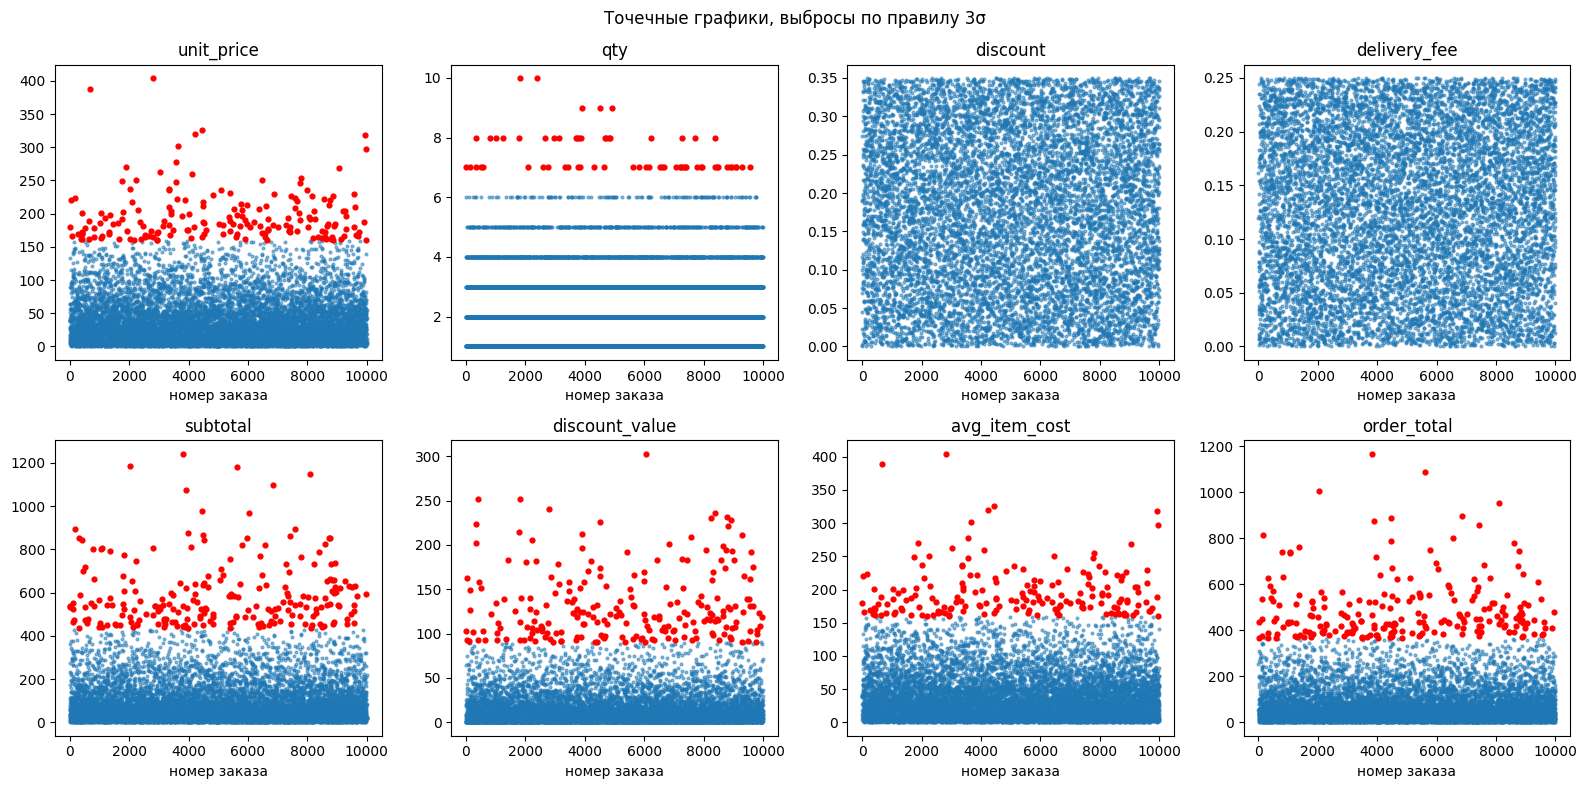

In [49]:
fix, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten() # расплющивает массив, то есть делает одномерным
x = np.arange(len(df))

for ax, col in zip(axes, df.columns):
    outline = outliners_mask[col].values

    ax.scatter(x[~outline], df[col][~outline], s=4, alpha=0.5, label='норма')
    ax.scatter(x[outline], df[col][outline], color='red', s=12, label='выброс')

    ax.set_title(col)
    ax.set_xlabel('номер заказа')

plt.suptitle("Точечные графики, выбросы по правилу 3σ")
plt.tight_layout()
plt.show()

гистограмму распределения случайной величины

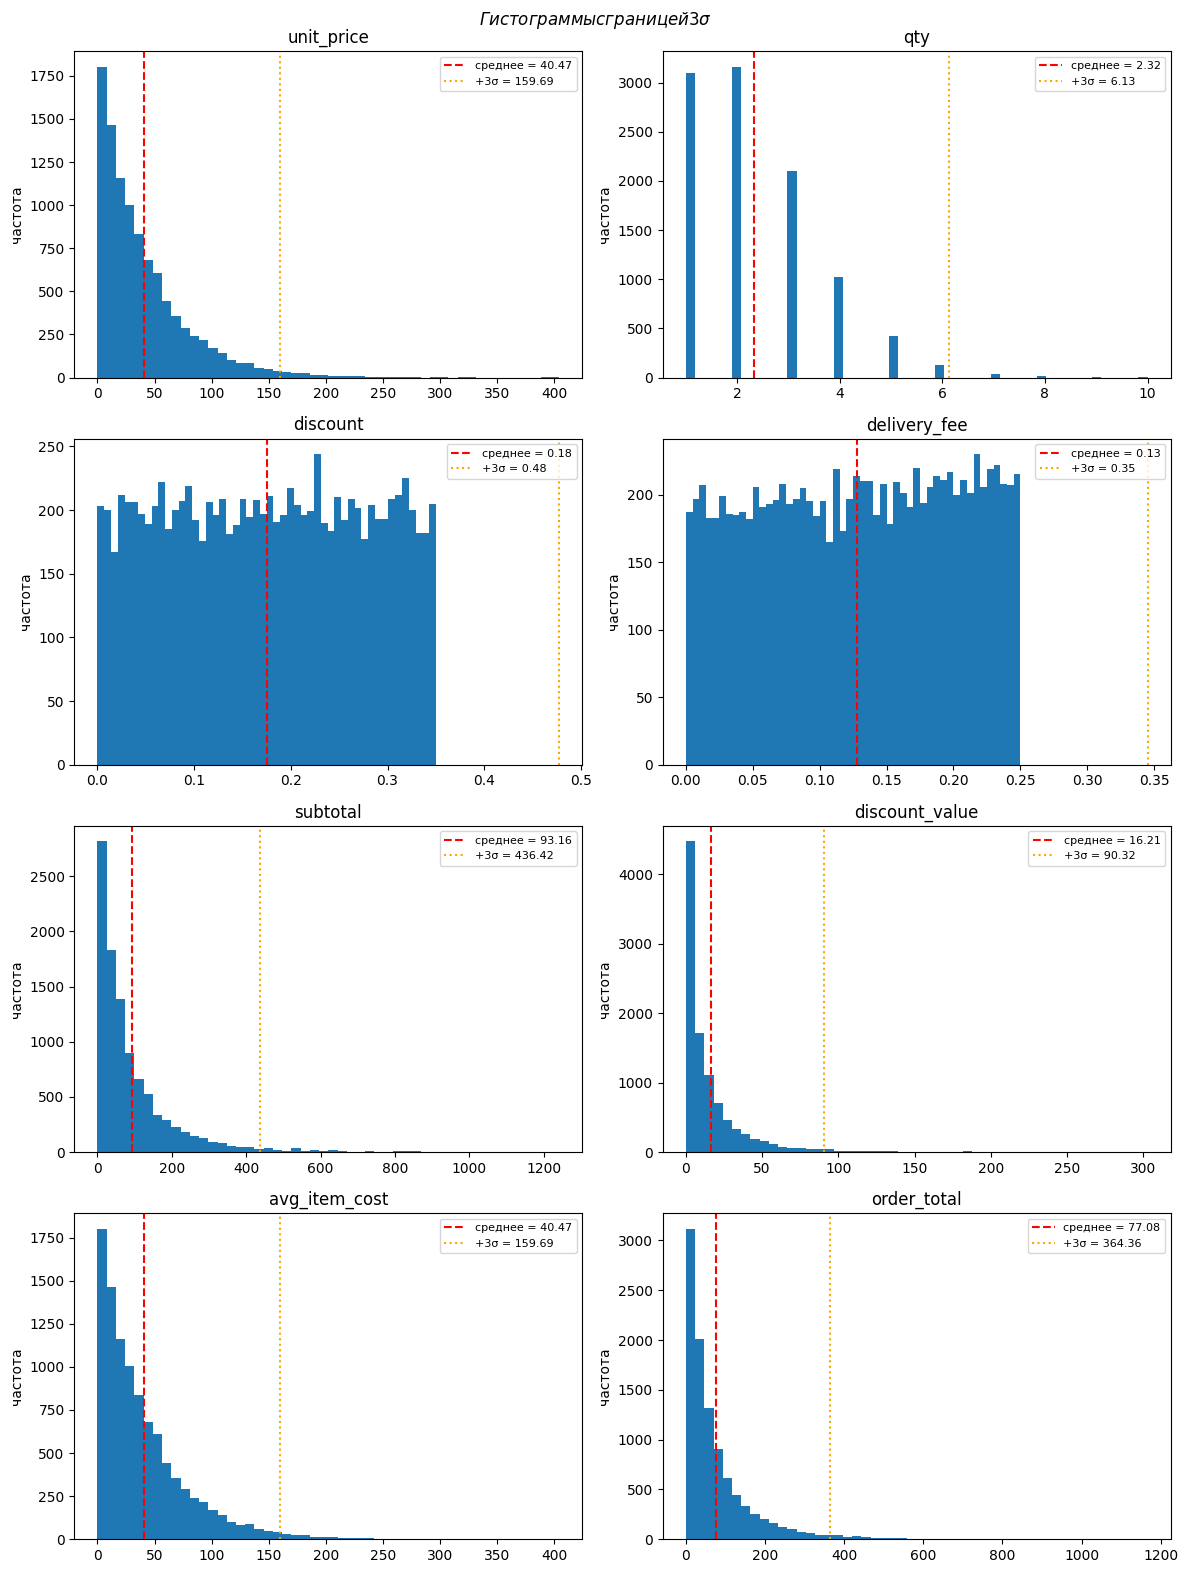

In [52]:
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
axes = axes.flatten()

for ax, col in zip(axes, df.columns):
    M = mean(df[col])
    std = var(df[col]) ** 0.5
    upper = M + 3 * std
    ax.hist(df[col], bins=50, color="tab:blue")
    ax.axvline(M, color="red", linestyle="--", label=f"среднее = {M:.2f}")
    ax.axvline(upper, color="orange", linestyle=":", label=f"+3σ = {upper:.2f}")
    ax.set_title(col)
    ax.set_ylabel("частота")
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle(r"$Гистограммы с границей 3\sigma$")
plt.tight_layout()
plt.show()

проверьте соотвествует ли гистограмма распределения случайной величины случайному распределению заданному вашим вариантом

* экспоненциальное: $f(x) = \frac{1}{\beta} e^{-x/\beta}$, β = 40
* равномерное на [a, b]: $f(x) = \frac{1}{b-a}$
* Пуассон без нуля: $P(k) = \frac{\lambda^k e^{-\lambda}}{k!\,(1 - e^{-\lambda})}$

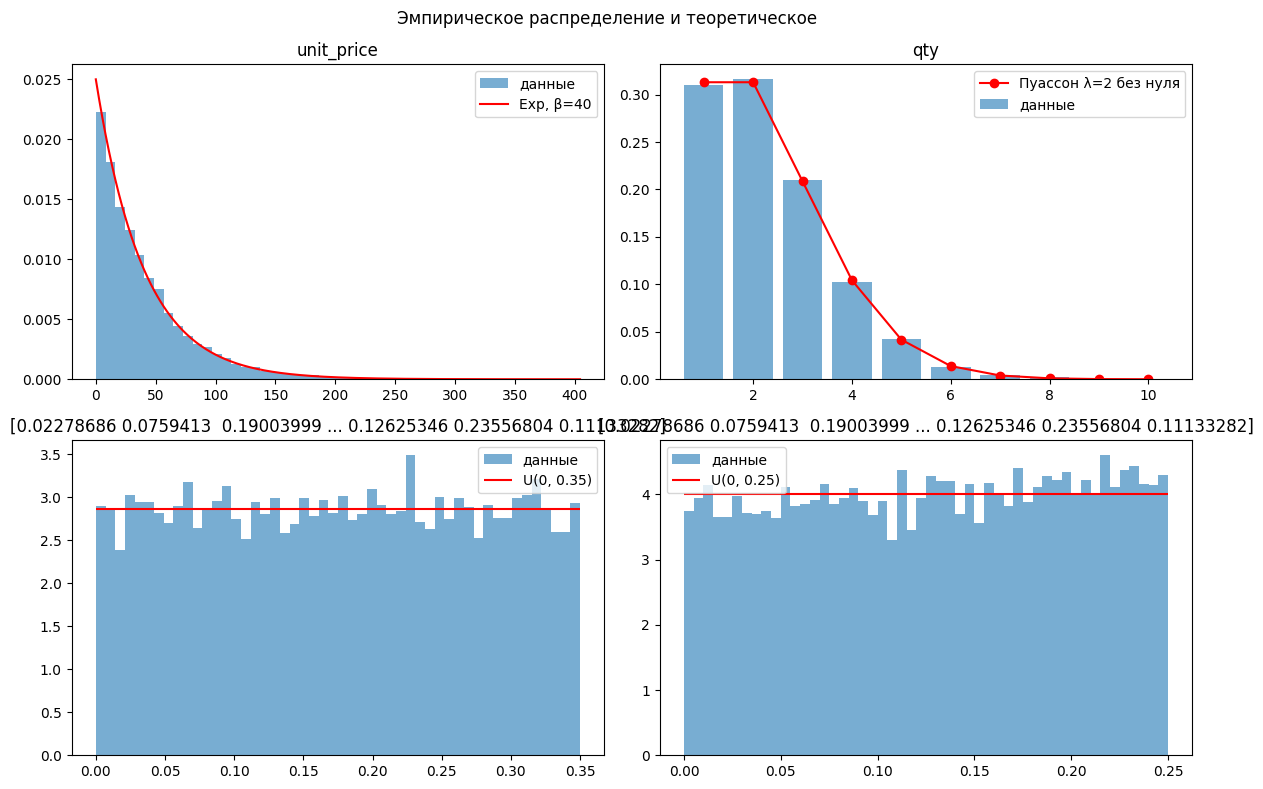

In [55]:
def factorial(k):
    result = 1
    for i in range(2, k + 1):
        result *= i
    return result


def density_exp(x, beta=40):
    return np.exp(-x / beta) / beta


def density_uniform(a, b):
    return 1 / (b - a)


def pmf_poisson(k, lam=2):
    return lam ** k * np.exp(-lam) / (factorial(k) * (1 - np.exp(-lam)))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

x = np.linspace(0, df["unit_price"].max(), 300)
axes[0, 0].hist(df["unit_price"], bins=50, density=True, alpha=0.6, label="данные")
axes[0, 0].plot(x, density_exp(x), color="red", label="Exp, β=40")
axes[0, 0].set_title("unit_price")

points = np.arange(1, df["qty"].max() + 1) # точки для распределения Пуассона, оно же дискретное, +1 потому что arange не включает правую границу

freq = np.array([np.sum(df["qty"] == k) / len(df) for k in points])
pmf = np.array([pmf_poisson(k) for k in points])
axes[0, 1].bar(points, freq, alpha=0.6, label="данные")
axes[0, 1].plot(points, pmf, "o-", color="red", label="Пуассон λ=2 без нуля")
axes[0, 1].set_title("qty")

a, b = 0, 0.35
axes[1, 0].hist(df['discount'], bins=50, density=True, alpha=0.6, label="данные")
axes[1, 0].hlines(density_uniform(a, b), a, b, color="red", label=f"U({a}, {b})")
axes[1, 0].set_title(discount)

a, b = 0, 0.25
axes[1, 1].hist(df['delivery_fee'], bins=50, density=True, alpha=0.6, label="данные")
axes[1, 1].hlines(density_uniform(a, b), a, b, color="red", label=f"U({a}, {b})")
axes[1, 1].set_title(discount)

for ax in axes.flatten():
    ax.legend()

plt.suptitle("Эмпирическое распределение и теоретическое")
plt.tight_layout()
plt.show()

тепловая карта коэффицентов корреляции между полями.

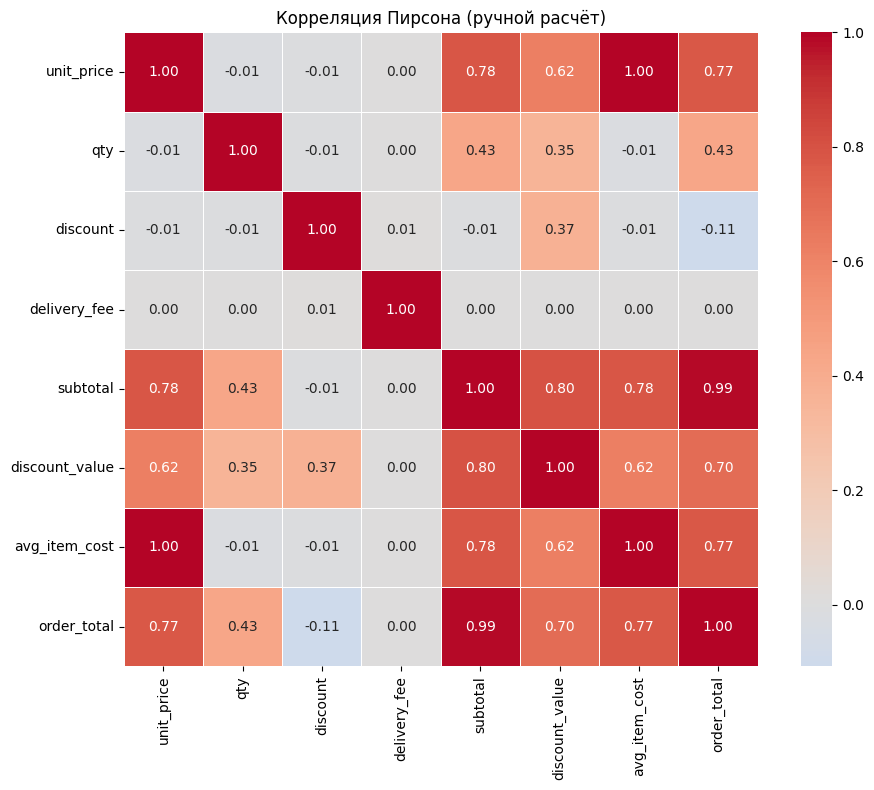

In [56]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Корреляция Пирсона (ручной расчёт)")
plt.tight_layout()
plt.show()